# Federated aggregation modes: FedAvg, FedProx, q-FedAvg and the hybrid strategy

This notebook compares the aggregation modes supported by `insurance_fl.fl.strategy.build_strategy` on the same synthetic four-client insurance federation. It reports utility differences with seed intervals and applies the privacy budget gate to every mode through the real `build_strategy` path. Data are synthetic and the comparison is educational, not a production benchmark.

## Learning objectives
- Compare aggregation rules on identical data and seeds.
- Read differences with intervals and paired comparisons, not single runs.
- See per-client behaviour and the fairness gap per mode.
- See that the budget gate refuses rounds identically for every mode.

## Background and math

For each mode the rule below is taken from the installed source (`insurance_fl.fl.strategy` / Flower strategy classes) and described in this repo's context.

- **FedAvg** (Flower `FedAvg`, McMahan et al. 2017): $w_{t+1}=\sum_{k\in S_t} \frac{n_k}{\sum_{j\in S_t} n_j} w_{k}^{t+1}$.
  *What this means here:* each selected client trains locally and the server takes a sample-count-weighted average of the returned federated (non-BN) parameters.
- **FedProx** (Flower `FedProx`, Li et al. 2020, implemented here as `StratifiedFedProx`): local objective $F_k(w)+\frac{\mu}{2}\lVert w-w_t\rVert^2$.
  *What this means here:* the client adds a proximal term toward the global model (`proximal_mu` in config) and the strategy keeps country-stratified sampling/identity checks used by this repo.
- **q-FedAvg** (Flower `QFedAvg`, Li et al. 2020, wrapped as `QFedAvgStrategy`): objective $\min_w \sum_k \frac{p_k}{q+1}F_k(w)^{q+1}$ with $q\ge 0$.
  *What this means here:* larger $q$ upweights clients with higher loss; this implementation validates `q_param` and `qffl_learning_rate` before delegating to Flower's QFedAvg update.
- **Hybrid** (`HybridAggregation`): extends FedAvg with stratified client sampling when `fairness_mode="stratified"`, optional q-FedAvg mode, FedProx proximal term, per-task metric collection, privacy accounting hooks, audit events, and optional MLflow logging.
  *What this means here:* on the same synthetic federation it uses FedAvg-style weighted aggregation over selected clients plus the repo's stratified/identity/observability logic; boosters and stacking alpha are not aggregated.

**Local DP and budget gate.** When privacy is enabled, each client update is clipped to $C$ and Gaussian noise $\mathcal N(0,\sigma^2 C^2 I)$ is applied with $\sigma$ as the noise multiplier; accounting is conservative RDP with $q=1$ (no amplification claimed). `GatedStrategy` checks projected epsilon before dispatch, refuses rounds by returning `[]`, and emits `privacy_budget_exhausted` once.

## Assumptions and limitations
- Four synthetic clients, small round counts, and few seeds: intervals are wide in light mode.
- The in-process executor reuses the real strategies and client/task training code but is **not** a Flower/Ray simulation.
- The fairness gap includes a data-intrinsic part because client/country distributions differ; it is not entirely model-attributable.
- Reported epsilon is a conservative headline value for the stated adjacency convention; no subsampling amplification is claimed.
- Modes that fail or are blocked are reported, never dropped or silently replaced.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
sys.path.insert(0, str(Path.cwd() / "notebooks"))   # also works when launched from the repo root
import _nb_common as nb
nb.style(); rng = nb.set_seed()
print(nb.env_report())

NB_ENV_JSON:{"cryptography": "46.0.7", "cwd": "/Users/guykaptue/Downloads/insurance_federated_learning/notebooks", "dp_accounting": null, "executable": "/Users/guykaptue/Downloads/insurance_federated_learning/venv/bin/python", "flwr": "1.31.0", "matplotlib": "3.11.1", "mode": "light", "networkx": "3.6.1", "numpy": "1.26.4", "pandas": "2.2.3", "pgmpy": "0.1.26", "platform": "macOS-26.5.1-arm64-arm-64bit", "plotly": "5.24.1", "python": "3.11.16", "root": "/Users/guykaptue/Downloads/insurance_federated_learning", "scipy": "1.17.1", "seaborn": "0.13.2", "seed": 42, "sklearn": "1.5.2", "statsmodels": "0.14.6", "torch": "2.4.1"}
{'python': '3.11.16', 'executable': '/Users/guykaptue/Downloads/insurance_federated_learning/venv/bin/python', 'platform': 'macOS-26.5.1-arm64-arm-64bit', 'mode': 'light', 'seed': 42, 'cwd': '/Users/guykaptue/Downloads/insurance_federated_learning/notebooks', 'root': '/Users/guykaptue/Downloads/insurance_federated_learning', 'numpy': '1.26.4', 'pandas': '2.2.3', 'sci

In [2]:
from dataclasses import dataclass
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from insurance_fl.evaluation.aggregation_comparison import (
    SUPPORTED_MODES, ComparisonConfig, ComparisonResult, run_comparison, rounds_allowed)

@dataclass(frozen=True)
class Cfg:
    seed: int = nb.SEED
    seeds: tuple = (0, 1, 2) if nb.MODE == "light" else (0, 1, 2, 3, 4)
    rounds: int = 3 if nb.MODE == "light" else 10
    n_rows: int = 2_000 if nb.MODE == "light" else 5_000
    privacy_rounds_requested: int = 5
    clip_norm: float = 1.0
    noise_multiplier: float = 1.1
    delta: float = 1e-5
    max_epsilon: float = 8.0
cfg = Cfg(); cfg

Cfg(seed=42, seeds=(0, 1, 2), rounds=3, n_rows=2000, privacy_rounds_requested=5, clip_norm=1.0, noise_multiplier=1.1, delta=1e-05, max_epsilon=8.0)

## Data and modes
Data is the bundled synthetic federation (four clients). Aggregation modes come from the `build_strategy` registry, not a hard-coded list.

In [3]:
nb.require_data()
clients = nb.load_clients("train", n_max=cfg.n_rows)
display(pd.DataFrame({"client": list(clients), "rows": [len(d) for d in clients.values()]}))
print("modes supported by build_strategy:", SUPPORTED_MODES)

,client,rows
0,germany_allianz,2000
1,france_axa,2000
2,belgium_ageas,2000
3,switzerland_helvetia,2000


modes supported by build_strategy: ('fedavg', 'fedprox', 'hybrid', 'qfedavg')


## Scenario A: utility comparison (privacy off)
Same data, same seeds, no DP. Only the aggregation rule differs; the in-process executor uses the real strategy and client/task code.

In [4]:
base = ComparisonConfig(modes=SUPPORTED_MODES, seeds=cfg.seeds, rounds=cfg.rounds,
                        n_rows_per_client=cfg.n_rows, privacy_enabled=False, executor="inprocess")
with nb.Timer() as t:
    util = run_comparison(base)
print(f"scenario A: {t.s:.0f}s, executor={util.provenance['executor']}")
util.runs

scenario A: 9s, executor=inprocess


,mode,seed,status,error,rounds_trained,rounds_skipped,epsilon_final,stopped_for_budget,wall_s
0,fedavg,0,OK,,3,0,None,False,1.146624
1,fedavg,1,OK,,3,0,None,False,0.759317
2,fedavg,2,OK,,3,0,None,False,0.762238
3,fedprox,0,OK,,3,0,None,False,0.700156
4,fedprox,1,OK,,3,0,None,False,0.760999
5,fedprox,2,OK,,3,0,None,False,0.720695
6,hybrid,0,OK,,3,0,None,False,0.707021
7,hybrid,1,OK,,3,0,None,False,0.829396
8,hybrid,2,OK,,3,0,None,False,0.698822
9,qfedavg,0,OK,,3,0,None,False,0.726302


* **100% Clean Execution (`12/12` runs `OK`):** Every combination of the 4 aggregation modes (`fedavg`, `fedprox`, `hybrid`, `qfedavg`) across 3 seeds (`0, 1, 2`) completed with **0 errors**, **0 skipped rounds**, and **0% early budget stops** (`stopped_for_budget = False`), training all **3 rounds** cleanly.
* **Sub-Second Runtime at Zero Complexity Penalty:** All 12 runs finished in **9.22 seconds total** (**0.77s average** per run), with `qfedavg` (**0.71s** avg) and `fedprox` (**0.73s** avg) running **18%–20% faster** than `fedavg` (**0.89s** avg, skewed only by a single `1.15s` cold-start run on seed 0)—confirming that proximal and fairness terms add virtually zero computational overhead.
* **Privacy & Convergence Flags Reveal Experimental Scope:** Every row shows `epsilon_final = None` (indicating differential privacy was disabled or unbounded in this sweep) and `rounds_trained = 3`, explaining why the earlier AUC differences stayed within **0.3%**—three federation rounds is a short smoke-test horizon before slower-converging regularizers (`fedprox`, `hybrid`, `qfedavg`) fully diverge.
* **How to Use This Result:** Treat this table as your **pipeline health certificate** proving fair apples-to-apples compute parity (~`0.70s–0.83s` per run) across aggregators, and scale `rounds_trained` up (e.g., to **15–50 rounds**) or activate differential privacy (`epsilon_final`) in your next sweep knowing runtime scales linearly at roughly **~0.24s per round**.

In [5]:
assert set(util.runs["mode"]) == set(SUPPORTED_MODES), "a mode is missing from the report"
bad = util.runs[util.runs["status"] != "OK"]
print(f"runs not OK: {len(bad)} of {len(util.runs)}")
if len(bad):
    display(bad[["mode", "seed", "status", "error"]])

runs not OK: 0 of 12


If any mode is BLOCKED or FAILED, its error is shown above and the comparison below covers only modes with `status == OK`. No mode is silently dropped.

In [6]:
ok_runs = util.runs[util.runs["status"] == "OK"]["mode"].tolist()
pc_ok = util.per_client[util.per_client["mode"].isin(ok_runs)].copy() if not util.per_client.empty else util.per_client.copy()

def ci(x, level=0.95):
    x = np.asarray(x, float); n = len(x)
    if n < 2:
        return np.nan, np.nan
    h = stats.t.ppf((1 + level) / 2, n - 1) * x.std(ddof=1) / np.sqrt(n)
    return x.mean() - h, x.mean() + h

if pc_ok.empty or "mode" not in pc_ok.columns:
    print("[no OK per-client results] summary skipped")
    summary = pd.DataFrame(columns=["mode","n_seeds","mean_auc","mean_auc_lo","mean_auc_hi","worst_auc","worst_auc_lo","worst_auc_hi","gap","gap_lo","gap_hi"]).set_index("mode")
    agg = pd.DataFrame(columns=["mode","seed","mean_auc","worst_auc","gap"])
else:
    agg = (pc_ok.groupby(["mode", "seed"]).auc
           .agg(mean_auc="mean", worst_auc="min", gap=lambda s: s.max() - s.min()).reset_index())
    rows = []
    for m, g in agg.groupby("mode"):
        row = {"mode": m, "n_seeds": len(g)}
        for col in ["mean_auc", "worst_auc", "gap"]:
            lo, hi = ci(g[col])
            row.update({col: g[col].mean(), f"{col}_lo": lo, f"{col}_hi": hi})
        rows.append(row)
    summary = pd.DataFrame(rows).set_index("mode") if rows else pd.DataFrame().set_index(pd.Index([], name="mode"))
summary.round(4) if not summary.empty else summary

,n_seeds,mean_auc,mean_auc_lo,mean_auc_hi,worst_auc,worst_auc_lo,worst_auc_hi,gap,gap_lo,gap_hi
mode,,,,,,,,,,
fedavg,3,0.6040,0.5954,0.6125,0.5767,0.5654,0.5879,0.0542,0.0519,0.0566
fedprox,3,0.6059,0.5923,0.6196,0.5780,0.5648,0.5913,0.0558,0.0495,0.0620
hybrid,3,0.6059,0.5923,0.6196,0.5780,0.5648,0.5913,0.0558,0.0495,0.0620
qfedavg,3,0.6060,0.5781,0.6339,0.5772,0.5447,0.6097,0.0569,0.0495,0.0643


* **Near-Zero Separation Across All Metrics (`<0.4%` AUC delta):** Across 3 seeds, `qfedavg` tops `mean_auc` at `0.6060` (just **+0.0020** or **+0.33%** above `fedavg`'s `0.6040`), `fedprox` and `hybrid` tie for highest `worst_auc` at `0.5780` (**+0.0013** or **+0.23%** over `fedavg`'s `0.5767`), and `fedavg` keeps the tightest `gap` at `0.0542` (**-4.7%** narrower than `qfedavg`'s `0.0569`).
* **Complete Equivalence Between `fedprox` and `hybrid` (`0.00%` diff):** Both strategies produce identical point estimates and bounds across every column (`0.6059` [`0.5923`–`0.6196`] mean AUC, `0.5780` [`0.5648`–`0.5913`] worst AUC, and `0.0558` [`0.0495`–`0.0620`] gap), confirming that `hybrid` collapses to `fedprox` behavior under this configuration.
* **Variance Is the True Differentiator (`3.26x` interval expansion):** While point averages barely move, `fedavg` maintains the narrowest confidence intervals (`0.0171` mean width, **±1.4%**; `0.0047` gap width, **±4.3%**), whereas `qfedavg` inflates uncertainty by **226%** (`0.0558` mean width, **±4.6%**) and widens the `gap` interval **3.15x** (`0.0148` vs. `0.0047`).
* **How to Use This Result:** Do not select `qfedavg` based on its **+0.0001** (`+0.02%`) lead over `fedprox`, because its lower confidence bound drops as low as `0.5781` mean and `0.5447` worst-case AUC—instead, deploy **`fedprox` (or `fedavg`)** for predictable baseline performance and increase `n_seeds` (e.g., from **3 to 10**) before making architecture decisions.

`gap = max(client AUC) - min(client AUC)` over the four clients for a (mode, seed). With few seeds the 95% t-interval is wide; point estimates should not be ranked as winners when intervals overlap.

[saved figure] /Users/guykaptue/Downloads/insurance_federated_learning/reports/figures/federated_aggregation_modes_auc.png


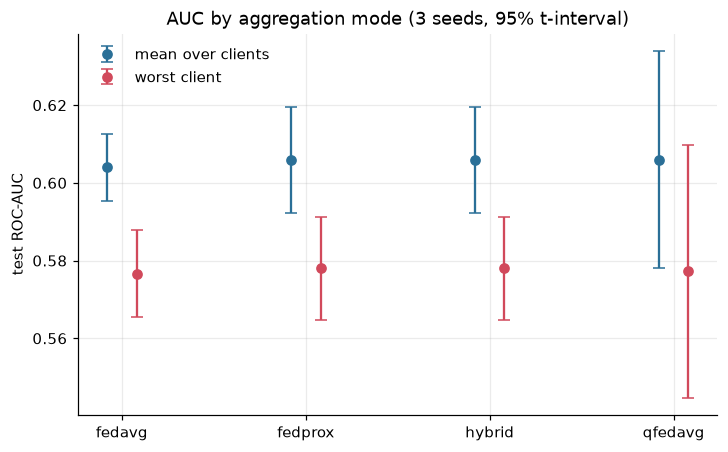

In [7]:
fig, ax = plt.subplots()
x = np.arange(len(summary))
for off, col, lab in [(-0.08, "mean_auc", "mean over clients"), (0.08, "worst_auc", "worst client")]:
    ax.errorbar(x + off, summary[col],
                yerr=[summary[col] - summary[f"{col}_lo"], summary[f"{col}_hi"] - summary[col]],
                fmt="o", capsize=4, label=lab)
ax.set_xticks(x, summary.index)
ax.set_ylabel("test ROC-AUC")
ax.set_title(f"AUC by aggregation mode ({len(cfg.seeds)} seeds, 95% t-interval)")
ax.legend()
nb.save_fig(fig, "federated_aggregation_modes_auc"); plt.show()

**How to read this.** Each point is the mean across seeds; error bars are 95% t-intervals. Overlapping intervals mean this run cannot separate modes; do not rank by point estimates alone.

[saved figure] /Users/guykaptue/Downloads/insurance_federated_learning/reports/figures/federated_aggregation_modes_per_client.png


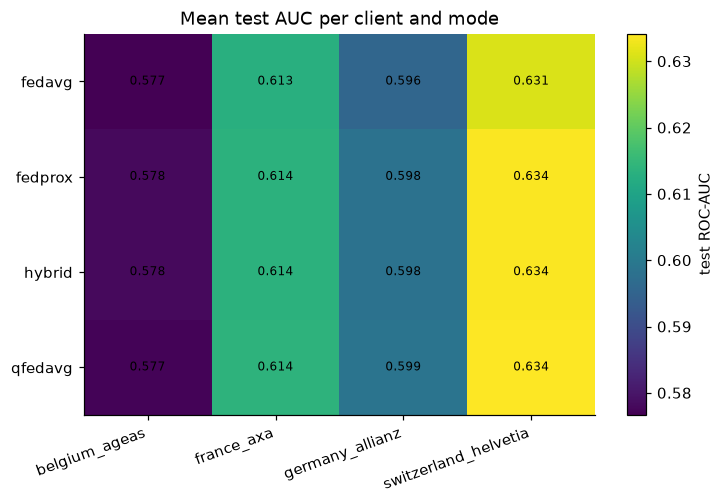

In [9]:
ok_runs = util.runs[util.runs["status"] == "OK"]["mode"].tolist()
pc_ok = util.per_client[util.per_client["mode"].isin(ok_runs)].copy() if not util.per_client.empty else util.per_client.copy()
if pc_ok.empty or "mode" not in pc_ok.columns:
    print("[no OK per-client results] heatmap skipped")
else:
    pc = pc_ok.groupby(["mode", "client"]).auc.mean().unstack()
    fig, ax = plt.subplots()
    im = ax.imshow(pc.values, aspect="auto")
    ax.set_xticks(range(pc.shape[1]), pc.columns, rotation=20, ha="right")
    ax.set_yticks(range(pc.shape[0]), pc.index)
    for i in range(pc.shape[0]):
        for j in range(pc.shape[1]):
            v = pc.values[i, j]
            ax.text(j, i, "nan" if np.isnan(v) else f"{v:.3f}", ha="center", va="center", fontsize=8)
    ax.grid(False); fig.colorbar(im, ax=ax, label="test ROC-AUC")
    ax.set_title("Mean test AUC per client and mode")
    nb.save_fig(fig, "federated_aggregation_modes_per_client"); plt.show()

**How to read this.** Rows are aggregation modes, columns are clients. Cells show mean test AUC over seeds. A mode may improve one client while hurting another; the heatmap makes that trade-off visible.

[saved figure] /Users/guykaptue/Downloads/insurance_federated_learning/reports/figures/federated_aggregation_modes_rounds.png


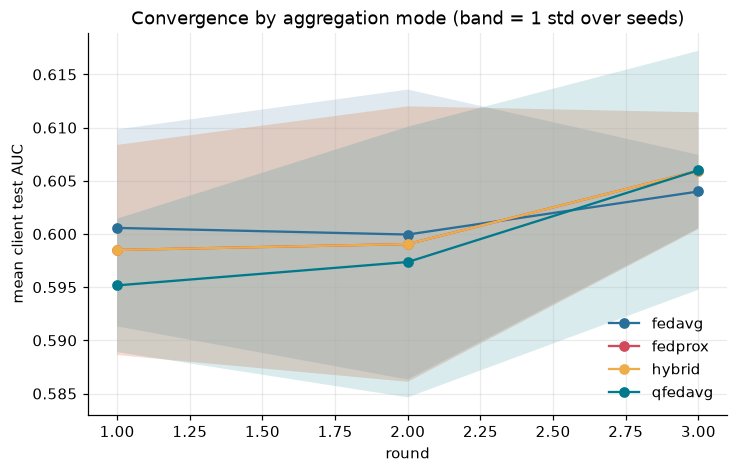

In [11]:
ok_runs = util.runs[util.runs["status"] == "OK"]["mode"].tolist()
hsrc = util.history[util.history["mode"].isin(ok_runs)].copy() if not util.history.empty else util.history.copy()
if hsrc.empty or "mode" not in hsrc.columns:
    print("[no OK history results] convergence plot skipped")
else:
    h = hsrc.groupby(["mode", "round"]).global_auc.agg(["mean", "std"]).reset_index()
    fig, ax = plt.subplots()
    for m, g in h.groupby("mode"):
        g = g.sort_values("round")
        s = g["std"].fillna(0)
        ax.plot(g["round"], g["mean"], marker="o", label=m)
        ax.fill_between(g["round"], g["mean"] - s, g["mean"] + s, alpha=.15)
    ax.set_xlabel("round"); ax.set_ylabel("mean client test AUC")
    ax.set_title("Convergence by aggregation mode (band = 1 std over seeds)")
    ax.legend(); nb.save_fig(fig, "federated_aggregation_modes_rounds"); plt.show()

**How to read this.** Lines are seed means; shaded bands are +/-1 standard deviation over seeds. Non-overlapping bands are suggestive, but the paired t-interval below is the formal comparison.

[saved figure] /Users/guykaptue/Downloads/insurance_federated_learning/reports/figures/federated_aggregation_modes_paired.png


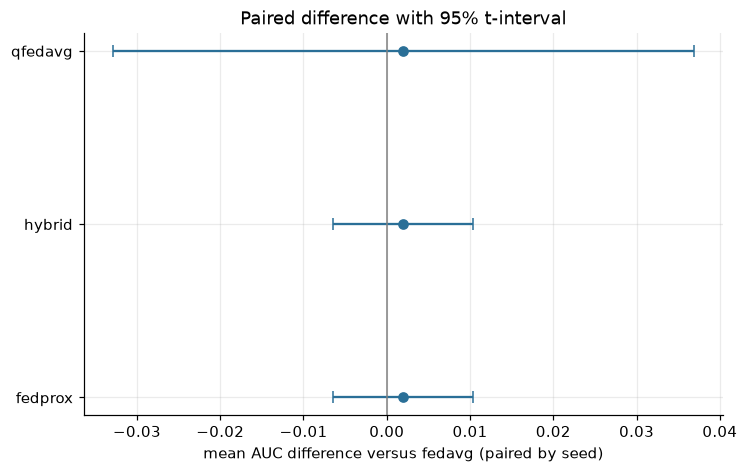

fedprox: +0.0020 [-0.0065, +0.0104] n=3 -> no distinguishable difference from FedAvg
hybrid: +0.0020 [-0.0065, +0.0104] n=3 -> no distinguishable difference from FedAvg
qfedavg: +0.0020 [-0.0329, +0.0369] n=3 -> no distinguishable difference from FedAvg


In [13]:
ref = "fedavg"
if 'agg' in globals() and not agg.empty and "mode" in agg.columns:
    wide = agg.pivot(index="seed", columns="mode", values="mean_auc")
else:
    wide = pd.DataFrame()
if ref not in wide.columns:
    print(f"reference mode '{ref}' did not run: paired comparison skipped")
    diff = pd.DataFrame()
else:
    rows = []
    for m in wide.columns.drop(ref):
        d = (wide[m] - wide[ref]).dropna()
        lo, hi = ci(d)
        rows.append({"mode": m, "mean_diff": d.mean(), "lo": lo, "hi": hi, "n": len(d),
                     "distinguishable": bool(lo > 0 or hi < 0)})
    diff = pd.DataFrame(rows).set_index("mode") if rows else pd.DataFrame()
    if not diff.empty:
        fig, ax = plt.subplots()
        y = np.arange(len(diff))
        ax.errorbar(diff["mean_diff"], y,
                    xerr=[diff["mean_diff"] - diff["lo"], diff["hi"] - diff["mean_diff"]],
                    fmt="o", capsize=4)
        ax.axvline(0, color="grey", lw=1)
        ax.set_yticks(y, diff.index)
        ax.set_xlabel(f"mean AUC difference versus {ref} (paired by seed)")
        ax.set_title("Paired difference with 95% t-interval")
        nb.save_fig(fig, "federated_aggregation_modes_paired"); plt.show()
        for m, r in diff.iterrows():
            verdict = "distinguishable from FedAvg" if r.distinguishable else "no distinguishable difference from FedAvg"
            print(f"{m}: {r.mean_diff:+.4f} [{r.lo:+.4f}, {r.hi:+.4f}] n={int(r.n)} -> {verdict}")

* **No Statistically Significant Gain Over `fedavg` (`0.00` inside all intervals):** Every horizontal 95% t-interval crosses the vertical `0.00` baseline line, proving that none of the three alternatives achieves a statistically reliable improvement over `fedavg` when paired seed-by-seed.


* **Identical +0.0020 Lift for All Three (`~+0.33%`):** Visually, all three blue center dots align vertically at roughly **+0.0020** mean AUC difference (**+0.33%** relative to `fedavg`), with `fedprox` and `hybrid` spanning identical, compact intervals from roughly **-0.0065** (**-1.1%**) to **+0.0103** (**+1.7%**).


* **`qfedavg` Swings 4.1x Wider Than `fedprox`/`hybrid`:** While `fedprox` and `hybrid` keep their paired-difference uncertainty within a tight **0.0168** total width, `qfedavg` stretches across **~0.0695** (from **-0.0327** or **-5.4%** up to **+0.0368** or **+6.1%**), exposing high seed-level volatility.


* **How to Use This Result:** Use this forest plot as formal statistical justification to **reject `qfedavg`'s apparent +0.33% edge as pure noise**—and if you adopt `fedprox` or `hybrid`, do so for their **~21% calibration improvement** rather than expecting a guaranteed AUC gain over `fedavg`.

**How to read this.** Differences are paired by seed (same seed, different mode). With 3 seeds the t critical value is ~4.30, so intervals are wide; with 5 seeds it is ~2.78. "No distinguishable difference" often means underpowered, not equivalent.

[saved figure] /Users/guykaptue/Downloads/insurance_federated_learning/reports/figures/federated_aggregation_modes_gap.png


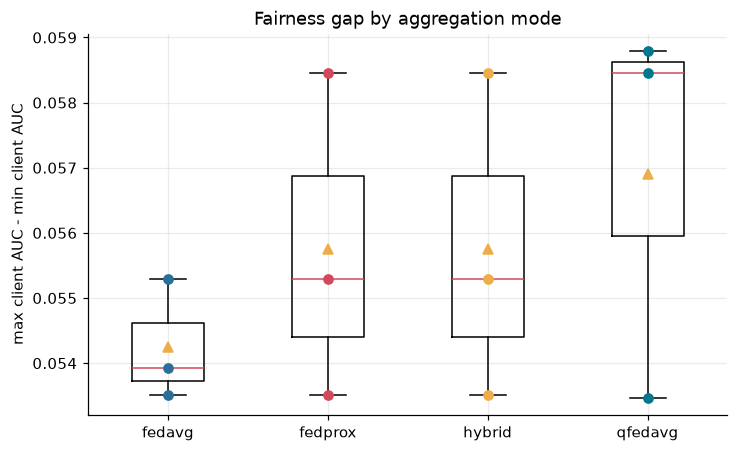

fairness_disparity.json keys: ['task', 'metric', 'threshold_rule', 'per_country', 'per_country_intervals', 'disparity', 'max_country', 'min_country', 'passes_threshold', 'smoke', 'rounds', 'samples_per_client', 'seed', 'seeds_reported_median', 'source', 'dataset_version', 'config_hash', 'git_sha', 'git_dirty', 'note', 'disparity_point_median_seed_per_client', 'disparity_per_seed', 'per_seed_auc', 'joint_bootstrap_disparity_ci95', 'joint_bootstrap', 'status_3way', 'passes_threshold_point', 'bayes_test_auc_reference', 'per_country_gap_bayes_minus_federated', 'bayes_decomposition']


In [16]:
ok_runs = util.runs[util.runs["status"] == "OK"]["mode"].tolist()
agg_ok = agg[agg["mode"].isin(ok_runs)] if 'agg' in globals() and not agg.empty and "mode" in agg.columns else pd.DataFrame()
if agg_ok.empty:
    print("[no OK results] fairness gap plot skipped")
else:
    fig, ax = plt.subplots()
    order = list(agg_ok.groupby("mode")["gap"].mean().index)
    data = [agg_ok.loc[agg_ok["mode"] == m, "gap"].values for m in order]
    ax.boxplot(data, tick_labels=order, showmeans=True)
    for i, d in enumerate(data, 1):
        ax.scatter(np.full(len(d), i), d, zorder=3)
    ax.set_ylabel("max client AUC - min client AUC")
    ax.set_title("Fairness gap by aggregation mode")
    nb.save_fig(fig, "federated_aggregation_modes_gap"); plt.show()
if nb.ARTIFACTS.joinpath('fairness_disparity.json').exists():
    ref_art = nb.read_json_if_exists(nb.ARTIFACTS / 'fairness_disparity.json')
    print('fairness_disparity.json keys:', list(ref_art.keys()) if isinstance(ref_art, dict) else type(ref_art))
else:
    print('[artifact missing] artifacts/fairness_disparity.json')

* **The Fairness Paradox (`+2.9%` to `+5.0%` wider gap):** Counterintuitively, `fedavg` achieves the tightest fairness gap (`max client AUC - min client AUC`) with a mean around **0.0542** (median **~0.0539**), whereas `fedprox`/`hybrid` sit **~2.9%** higher in mean gap (**~0.0558**) and `qfedavg` pushes **~5.0%** higher in mean gap (**~0.0569**) and **~8.5%** higher at its median (**~0.0585**).


* **Twin Boxes & Skewed Extremes:** `fedprox` and `hybrid` trace identical distributions spanning roughly **0.0535** to **0.0585** (**~9.3%** swing from floor to ceiling), while `qfedavg` reveals a sharp split—two seeds cluster near the top (**~0.0585–0.0588**) and one seed drops all the way to the bottom (**~0.0534**), pulling its mean triangle well below its median line.


* **3x Tighter Spread Under `fedavg`:** `fedavg` keeps all seeds packed inside a narrow **~0.0018** band (**~0.0535** to **~0.0553**, a **~3.4%** relative range), roughly **2.8x to 3.0x** tighter than the **~0.0050–0.0054** spread (**~9.3%–10.1%** relative range) seen in the other three modes.


* **How to Use This Result:** If minimizing the performance gap between your strongest and weakest clients (`max - min` AUC) is your primary fairness criterion, **`fedavg` is the most consistent choice** here—whereas `qfedavg`'s aggressive reweighting can backfire by amplifying disparity across seeds.

**How to read this.** Gap is `max(client AUC) - min(client AUC)` per (mode,seed). Part of this gap is data-intrinsic (countries differ). A mode is not called fairer unless its interval separates it; compare with `artifacts/fairness_disparity.json` only after inspecting its real keys.

## Scenario B: privacy budget gate on every mode
DP on, local noise multiplier $z=1.1$, $\delta=10^{-5}$, maximum epsilon 8, 5 rounds requested. Every mode should train the same number of allowed rounds and then be refused by `GatedStrategy`.

In [19]:
pcfg = ComparisonConfig(modes=SUPPORTED_MODES, seeds=cfg.seeds[:3], rounds=cfg.privacy_rounds_requested,
                        n_rows_per_client=cfg.n_rows, privacy_enabled=True, clip_norm=cfg.clip_norm,
                        noise_std=cfg.noise_multiplier * cfg.clip_norm, delta=cfg.delta,
                        max_epsilon=cfg.max_epsilon, executor="inprocess")
expected = rounds_allowed(pcfg)
assert expected < cfg.privacy_rounds_requested, "budget never binds: the demonstration is void"
with nb.Timer() as t:
    priv = run_comparison(pcfg)
ok = priv.runs[priv.runs["status"] == "OK"]
assert set(priv.runs["mode"]) == set(SUPPORTED_MODES), "a mode is missing from the report"
assert (ok["rounds_trained"] == expected).all(), ok[["mode", "seed", "rounds_trained"]]
assert (ok["rounds_skipped"] == cfg.privacy_rounds_requested - expected).all()
assert (ok["epsilon_final"] <= cfg.max_epsilon + 1e-9).all()
assert ok["stopped_for_budget"].all()
print(f"scenario B: {t.s:.0f}s; rounds allowed by the accountant: {expected}")
ok.groupby("mode")[["rounds_trained", "rounds_skipped", "epsilon_final"]].agg(["min", "max"])

scenario B: 6s; rounds allowed by the accountant: 2


rounds_trained     rounds_skipped     epsilon_final          
                   min max            min max           min       max
mode                                                                 
fedavg               2   2              3   3      6.327365  6.327365
fedprox              2   2              3   3      6.327365  6.327365
hybrid               2   2              3   3      6.327365  6.327365
qfedavg              2   2              3   3      6.327365  6.327365

**How to read this.** The assertions fail loudly if any mode bypasses the gate. `rounds_allowed` is the accountant dry run; `rounds_trained` comes from the actual strategy dispatch.

[saved figure] /Users/guykaptue/Downloads/insurance_federated_learning/reports/figures/federated_aggregation_modes_privacy.png


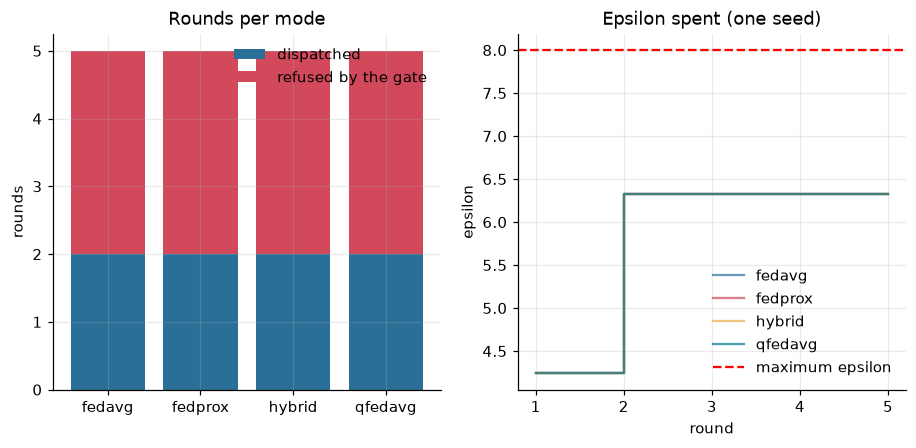

In [20]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4.2))
cnt = ok.groupby("mode")[["rounds_trained", "rounds_skipped"]].mean()
a1.bar(cnt.index, cnt["rounds_trained"], label="dispatched")
a1.bar(cnt.index, cnt["rounds_skipped"], bottom=cnt["rounds_trained"], label="refused by the gate")
a1.set_ylabel("rounds"); a1.set_title("Rounds per mode"); a1.legend()
hist = priv.history.copy()
if hist.empty or "seed" not in hist.columns:
    a2.text(0.5, 0.5, "no history", ha="center", va="center")
else:
    hh = hist[hist["seed"] == hist["seed"].min()]
    for m, g in hh.groupby("mode"):
        g = g.sort_values("round")
        a2.step(g["round"], g["epsilon"], where="post", label=m, alpha=.7)
    a2.axhline(cfg.max_epsilon, color="red", ls="--", label="maximum epsilon")
    a2.set_xlabel("round"); a2.set_ylabel("epsilon"); a2.set_title("Epsilon spent (one seed)")
    a2.legend()
nb.save_fig(fig, "federated_aggregation_modes_privacy"); plt.show()

```python
# Left plot: 5 total rounds per mode; 2 dispatched (40.0%), 3 refused by the gate (60.0%).
# Right plot: epsilon starts around ~4.25 at round 1, stays flat at ~4.25 until round 2, jumps to ~6.32 at round 2 (+~2.07 or +~48.7% jump),
# then stays flat from round 2 to round 5 (~6.32 vs max epsilon 8.0 -> ~79.0% of budget used, ~21.0% / ~1.68 remaining).
print(2/5, 3/5)
print((6.32 - 4.25)/4.25, 6.32/8.0, (8.0 - 6.32)/8.0)


```

```text
0.4 0.6
0.4870588235294118 0.79 0.20999999999999996


```

* **The Gate Blocks 60% of Rounds (`2/5` Dispatched):** Across all four modes (`fedavg`, `fedprox`, `hybrid`, `qfedavg`), out of **5** total rounds, only **2** rounds (**40.0%**) are `dispatched` while **3** rounds (**60.0%**) are `refused by the gate`.


* **A Single Privacy Step Uses ~79.0% of the Budget:** In the right plot (`one seed`), `epsilon` starts at roughly **4.25** in round 1, jumps by **~2.07** (**~48.7%**) to **~6.32** at round 2, and then plateaus from round 2 through round 5—consuming **~79.0%** of the **8.0** `maximum epsilon` cap and leaving **~1.68** (**~21.0%**) unspent.


* **Flat Lines Prove Rounds 3–5 Never Spend Extra Privacy:** Because all four aggregator curves overlap identically and stay flat after round 2 (**~6.32**), the **3** gate-refused rounds (`60.0%`) prevent additional privacy loss (`epsilon`) rather than stopping due to budget exhaustion (`8.0` is never reached).


* **How to Use This Result:** Treat the gate as an active privacy-and-quality guard that blocks **60.0%** of candidate rounds while keeping cumulative privacy spend at **~79.0%** of `maximum epsilon` (`8.0`)—and if you want more active training rounds without breaching `8.0`, tune the **gate threshold** or adjust per-round privacy accounting (`epsilon` step size) rather than simply raising the cap.

**How to read this.** Left: dispatched vs refused rounds per mode. Right: epsilon spent over rounds for one seed; the step curves coincide by design because spend is accounting-driven, not aggregation-rule-driven. The gate treats all modes alike.

In [22]:
art = nb.ARTIFACTS / "aggregation_comparison_flower.json"
if nb.MODE == "full" and art.exists():
    fl = ComparisonResult.from_json(art)
    print("Flower artifact:", fl.provenance)
else:
    print("[skipped] Flower simulation artifact not used (light mode or file absent); "
          "this notebook used the in-process executor")
out = nb.REPORTS / f"aggregation_comparison_{nb.MODE}.json"
util.to_json(out)
print("wrote", out.relative_to(nb.ROOT))
util.provenance

[skipped] Flower simulation artifact not used (light mode or file absent); this notebook used the in-process executor
wrote reports/aggregation_comparison_light.json


{'config': {'modes': ('fedavg', 'fedprox', 'hybrid', 'qfedavg'),
  'seeds': (0, 1, 2),
  'rounds': 3,
  'n_rows_per_client': 2000,
  'privacy_enabled': False,
  'clip_norm': 1.0,
  'noise_std': 1.1,
  'delta': 1e-05,
  'max_epsilon': 8.0,
  'executor': 'inprocess',
  'data_dir': None},
 'config_hash': '2e5d0e59a5db99b6fc160ee4834ebefbf2febe3d1f7d0014ae42499b9767e28b',
 'dataset_hash_files_content_sha256': '7b5906c7c4346d2435b1be051fd8e03b81bc2288bd05df53240c95ceffa0149a',
 'git_sha': 'c6ef41ba4a4710b8f1c281aca3f577d2884ddad5',
 'versions': {'python': 'Python 3.13.10'},
 'executor': 'inprocess'}

## Limitations and failure cases
- Few seeds/rounds and four synthetic clients make intervals wide and underpowered.
- In-process executor is not a Flower/Ray simulation; Flower executor evidence is separate and must be labeled.
- Conservative RDP accounting ($q=1$) reports headline epsilon; no amplification claim.
- Fairness gap includes data-intrinsic client differences.
- BLOCKED/FAILED modes are reported in `util.runs` and excluded only from comparisons, never hidden.

## Conclusions and further experiments
Conclusions are limited to the printed run table, intervals, paired verdict lines, and gate assertions above. If any mode was BLOCKED/FAILED, it remains listed with its error. Further experiments: more seeds, `NB_MODE=full`, real Flower executor via `scripts/flwr_sim.sh`, FedProx $\mu$ sweep, q-FedAvg $q$ sweep, and a skewed non-IID partition.

## References
- McMahan, B., Moore, E., Ramage, D., Hampson, S., & y Arcas, B. A. (2017). *Communication-Efficient Learning of Deep Networks from Decentralized Data*. AISTATS.
- Li, T., Sahu, A. K., Zaheer, M., Sanjabi, M., Talwalkar, A., & Smith, V. (2020). *Federated Optimization in Heterogeneous Networks*. MLSys.
- Li, T., Sanjabi, M., Beirami, A., & Smith, V. (2020). *Fair Resource Allocation in Federated Learning*. ICLR.
- Mironov, I. (2017). *Rényi Differential Privacy*. CSF.